In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Find the Wholesale customers dataset
possible_paths = [
    Path("../data/Wholesale customers data.csv"),
    Path("../Wholesale customers data.csv"),
    Path("../../Wholesale customers data.csv"),
]

file_path = next((p for p in possible_paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        "Could not find 'Wholesale customers data.csv'. "
        "Check that it is saved in the project data folder."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:

# Inspect the dataset
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe())

print("\nColumn names:")
print(df.columns.tolist())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values in each column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0

Summary statistics:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000



Column names:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


In [3]:

from sklearn.preprocessing import StandardScaler

# Select numerical spending features
exclude_columns = ["Channel", "Region"]
feature_columns = [
    col for col in df.select_dtypes(include=["number"]).columns
    if col not in exclude_columns
]

X = df[feature_columns].copy()

# Handle missing values, if any
X = X.fillna(X.median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature preparation successful!")
print("Features used for clustering:", feature_columns)
print("Scaled data shape:", X_scaled.shape)
print("Missing values remaining:", X.isnull().sum().sum())


Feature preparation successful!
Features used for clustering: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Scaled data shape: (440, 6)
Missing values remaining: 0


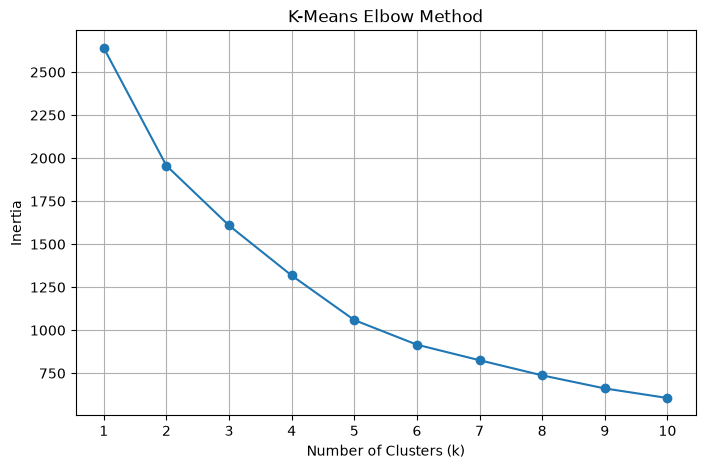

In [4]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Calculate inertia for different numbers of clusters
inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [5]:

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Fit K-Means with 5 clusters
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

# Evaluate clustering quality
print("K-MEANS CLUSTERING RESULTS")
print("-" * 40)
print("Number of clusters:", len(set(kmeans_labels)))
print("Silhouette Score:", round(
    silhouette_score(X_scaled, kmeans_labels), 4
))
print("Davies-Bouldin Index:", round(
    davies_bouldin_score(X_scaled, kmeans_labels), 4
))
print("Calinski-Harabasz Score:", round(
    calinski_harabasz_score(X_scaled, kmeans_labels), 4
))

print("\nCustomers in each cluster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())


K-MEANS CLUSTERING RESULTS
----------------------------------------
Number of clusters: 5
Silhouette Score: 0.369
Davies-Bouldin Index: 0.9125
Calinski-Harabasz Score: 162.4134

Customers in each cluster:
0    270
1     10
2     63
3     96
4      1
Name: count, dtype: int64


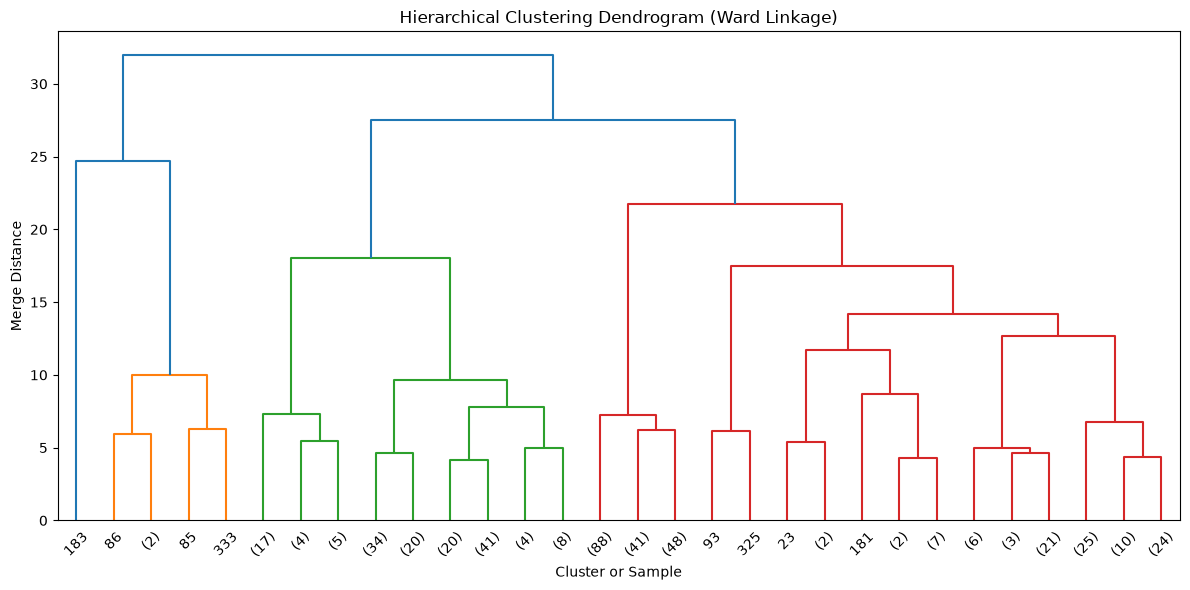

In [6]:

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Calculate hierarchical linkage using Ward's method
hierarchical_linkage = linkage(
    X_scaled,
    method="ward"
)

# Plot the dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    hierarchical_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster or Sample")
plt.ylabel("Merge Distance")
plt.tight_layout()
plt.show()


In [7]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

linkage_methods = ["ward", "complete", "average", "single"]
linkage_results = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=5,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    linkage_results.append({
        "Linkage": method.capitalize(),
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_scaled, labels
        )
    })

linkage_df = pd.DataFrame(linkage_results)

display(linkage_df.round(4))


,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Ward,0.2399,0.9727,128.6450
1,Complete,0.7085,0.4877,89.0257
2,Average,0.7368,0.4484,75.7973
3,Single,0.7345,0.1398,44.5669


In [8]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Train Agglomerative Hierarchical Clustering
agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

# Evaluate the model
print("AGGLOMERATIVE CLUSTERING RESULTS")
print("-" * 40)
print("Number of clusters:", len(set(agg_labels)))
print("Silhouette Score:", round(
    silhouette_score(X_scaled, agg_labels), 4
))
print("Davies-Bouldin Index:", round(
    davies_bouldin_score(X_scaled, agg_labels), 4
))
print("Calinski-Harabasz Score:", round(
    calinski_harabasz_score(X_scaled, agg_labels), 4
))

print("\nCustomers in each cluster:")
print(pd.Series(agg_labels).value_counts().sort_index())


AGGLOMERATIVE CLUSTERING RESULTS
----------------------------------------
Number of clusters: 5
Silhouette Score: 0.2399
Davies-Bouldin Index: 0.9727
Calinski-Harabasz Score: 128.645

Customers in each cluster:
0    153
1      5
2    104
3      1
4    177
Name: count, dtype: int64


Variance explained by two components: 0.7246


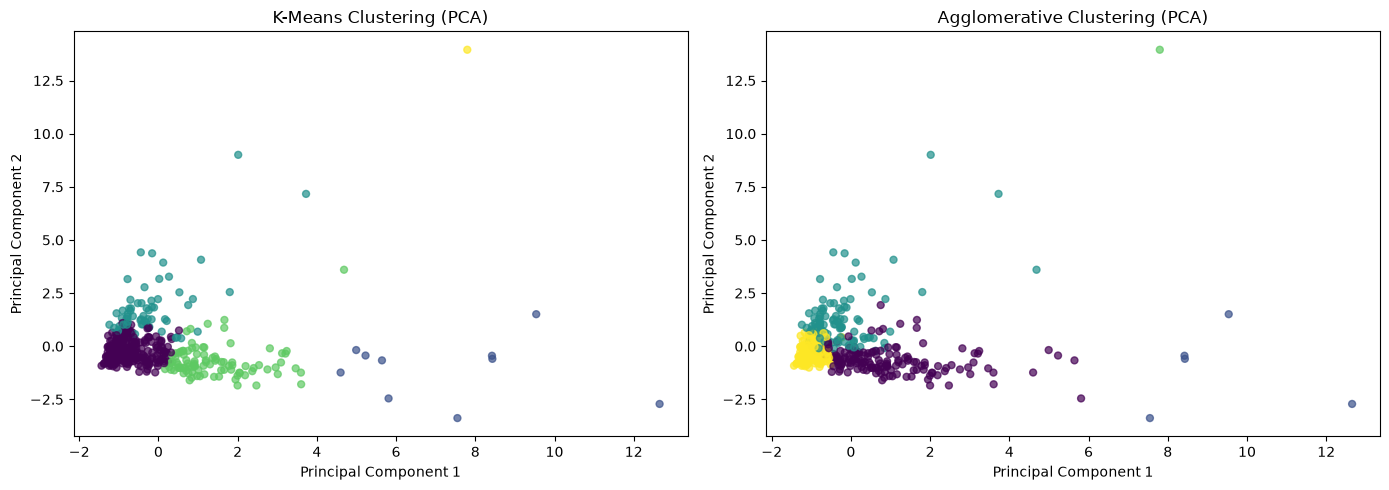

In [9]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the data to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# Plot both clustering algorithms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=kmeans_labels, cmap="viridis",
    s=25, alpha=0.7
)
axes[0].set_title("K-Means Clustering (PCA)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=agg_labels, cmap="viridis",
    s=25, alpha=0.7
)
axes[1].set_title("Agglomerative Clustering (PCA)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


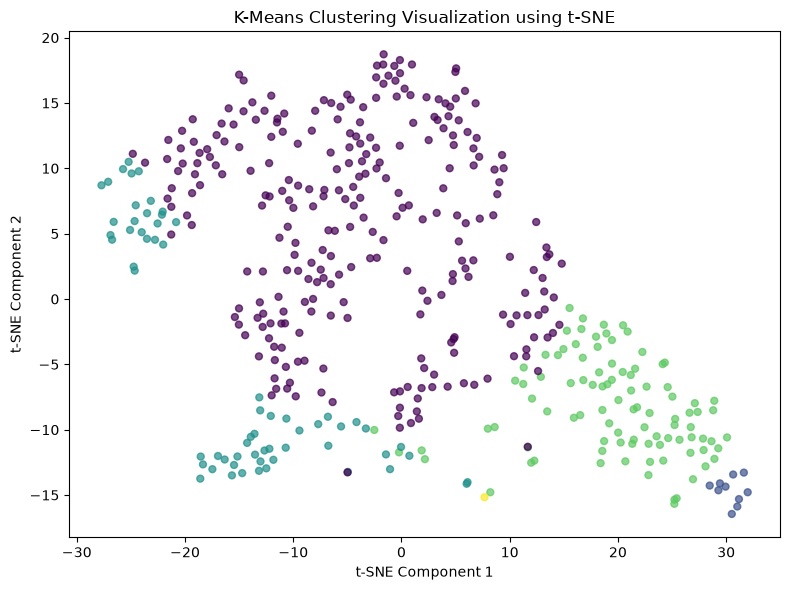

In [10]:

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Reduce the data to two dimensions using t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

# Visualize K-Means clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.title("K-Means Clustering Visualization using t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.tight_layout()
plt.show()


In [11]:

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

clustering_results = []

models_to_compare = {
    "K-Means": kmeans_labels,
    "Agglomerative (Ward)": agg_labels
}

for name, labels in models_to_compare.items():
    clustering_results.append({
        "Algorithm": name,
        "Number of Clusters": len(set(labels)),
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled, labels
        ),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_scaled, labels
        )
    })

clustering_comparison_df = pd.DataFrame(clustering_results)

display(clustering_comparison_df.round(4))


,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,5,0.3690,0.9125,162.4134
1,Agglomerative (Ward),5,0.2399,0.9727,128.6450


### Clustering Results and Conclusion

The Wholesale Customers dataset was clustered using K-Means and Agglomerative Hierarchical Clustering. The number of clusters was set to five based on the Elbow method.

The Agglomerative model was evaluated using Ward, Complete, Average, and Single linkage strategies. Both K-Means and Agglomerative clustering were assessed using the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score. PCA visualizations were created for both algorithms, and t-SNE was used to visualize the K-Means clusters.

For the five-cluster configuration, K-Means achieved a Silhouette Score of 0.3690, a Davies-Bouldin Index of 0.9125, and a Calinski-Harabasz Score of 162.4134. Agglomerative clustering with Ward linkage achieved 0.2399, 0.9727, and 128.6450, respectively.

Based on these three metrics, K-Means produced better-separated clusters than Agglomerative clustering with Ward linkage for this configuration.